# Constraints on $\mu$ for subluminal chains without the quasi-static approximation (DS1, linear CMB lensing, preliminary)

Without the QSA, $\mu(k, a) = (r_1 + x\,\mu_\infty)/(r_1 + x)$ with $x = (k/aH)^2$ and $r_1 = \mu_p/c_{sN}^2$ (Cataneo+2024 eq. 31a). $\mu_\infty$ is the QSA expression, reached for $k \gtrsim 10^{-2}\,h/\mathrm{Mpc}$; the transition happens near the horizon scale.

The QSA chains (94-97, linear lensing, the exact QSA counterparts of 113-116) are processed with the same function, using each sample's own $\omega_b h^2$ (the paper figures, made with `get_mu_alphas_from_chain`, use a fixed $\omega_b h^2 = 0.0122$).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import utils

In [2]:
indices = range(113, 116+1)
qsa_indices = [94, 95, 96, 97]
names = ["omega", "kessence", "prop", "cugal"]
aktypes = [1, 2, 4, 3]
k_values = [1e-4, 3e-4, 1e-3] # h/Mpc
mu_infs_all = []
mu_ks_all = []
mu_qsa_all = []

for i, (chain_index, qsa_index, name, aktype, color) in enumerate(zip(indices, qsa_indices, names, aktypes, utils.colors)):
    chain = utils.load_chain(chain_index, burn_in=0.2)
    log_a, mu_infs, mu_ks = utils.get_mu_k_from_chain(chain, aktype=aktype, k_values=k_values, num_samples=1_000)
    mu_infs_all.append(mu_infs)
    mu_ks_all.append(mu_ks)

    chain = utils.load_chain(qsa_index, burn_in=0.2)
    log_a, mu_qsa, _ = utils.get_mu_k_from_chain(chain, aktype=aktype, k_values=[], num_samples=1_000, use_qsa=True)
    mu_qsa_all.append(mu_qsa)

Number of samples = 46454
Number of samples after thinning = 1010


Number of samples = 47337
Number of samples after thinning = 1008


Number of samples = 47477
Number of samples after thinning = 1011


Number of samples = 56222
Number of samples after thinning = 1004


Number of samples = 10234
Number of samples after thinning = 1024


Number of samples = 39550
Number of samples after thinning = 1015


Number of samples = 9748
Number of samples after thinning = 1084


Number of samples = 48929
Number of samples after thinning = 1020


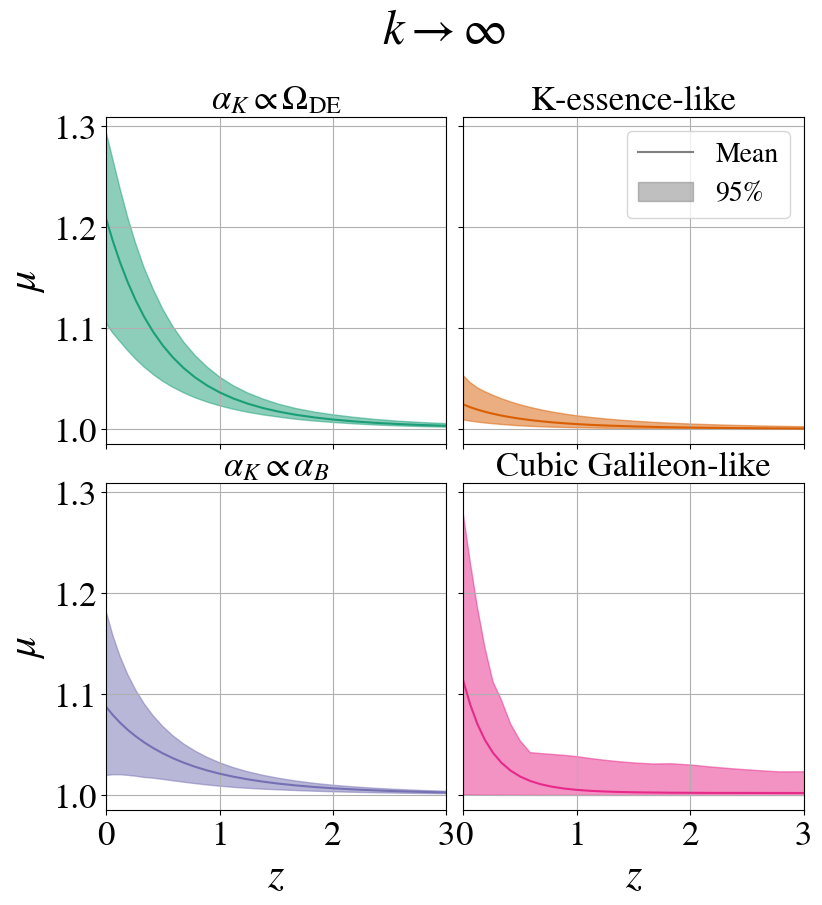

In [3]:
utils.plot_mu_distribution(log_a, mu_infs_all, "plots/constraint_mu_ds1_subluminal_noqsa.pdf", plot_title="$k \\to \\infty$")

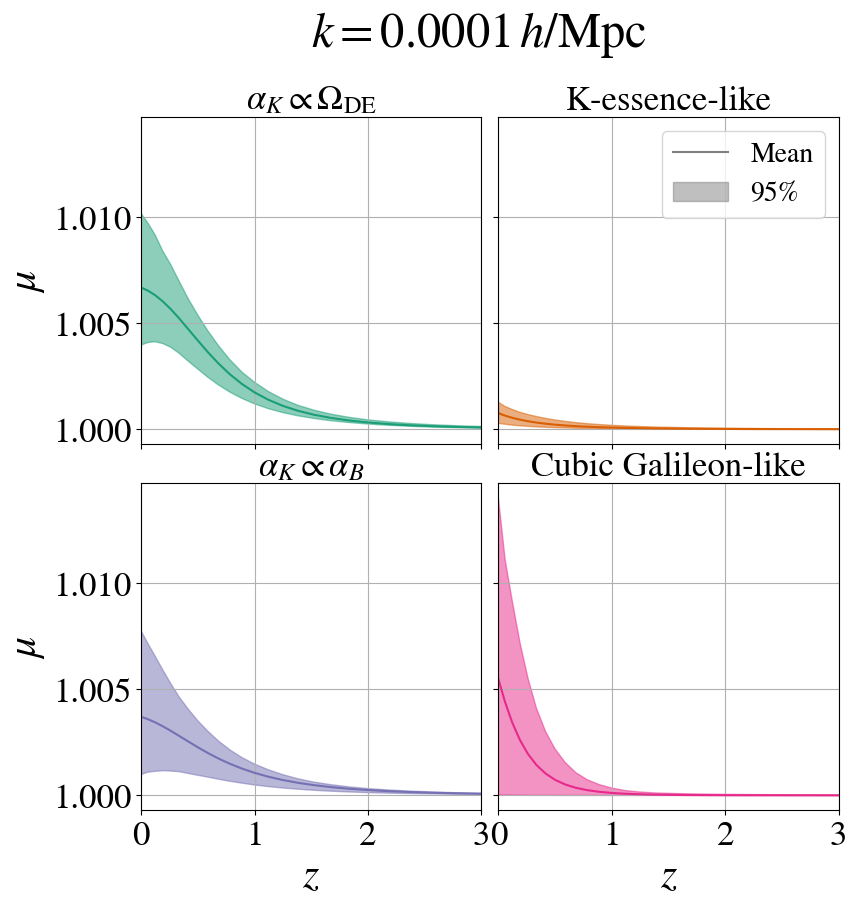

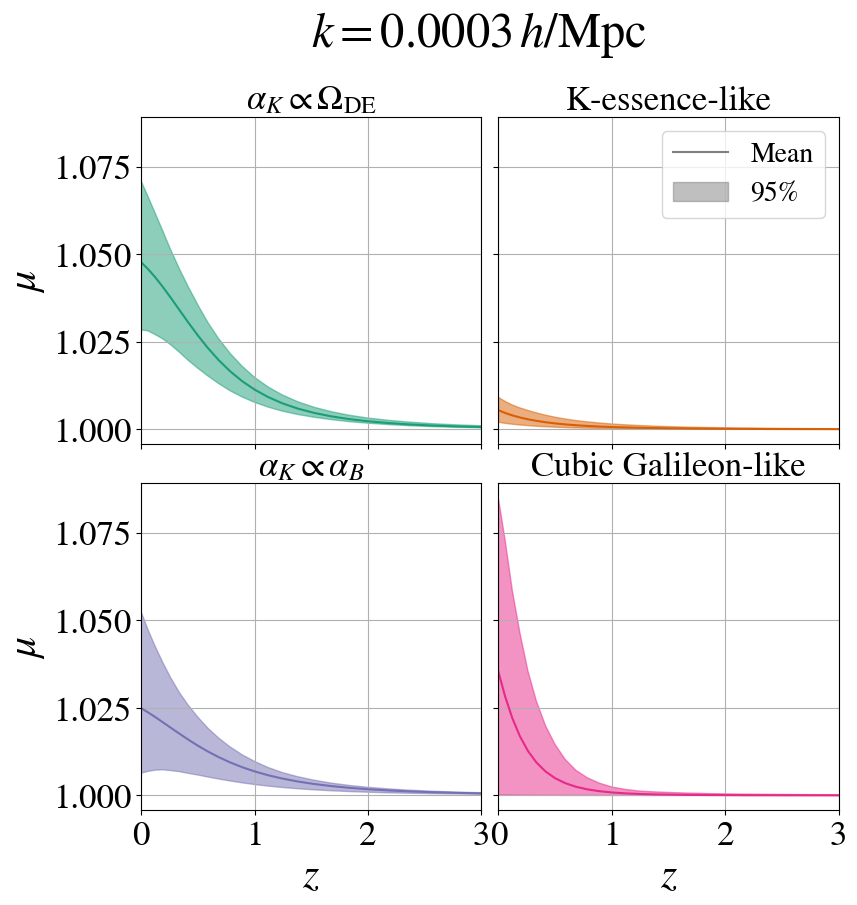

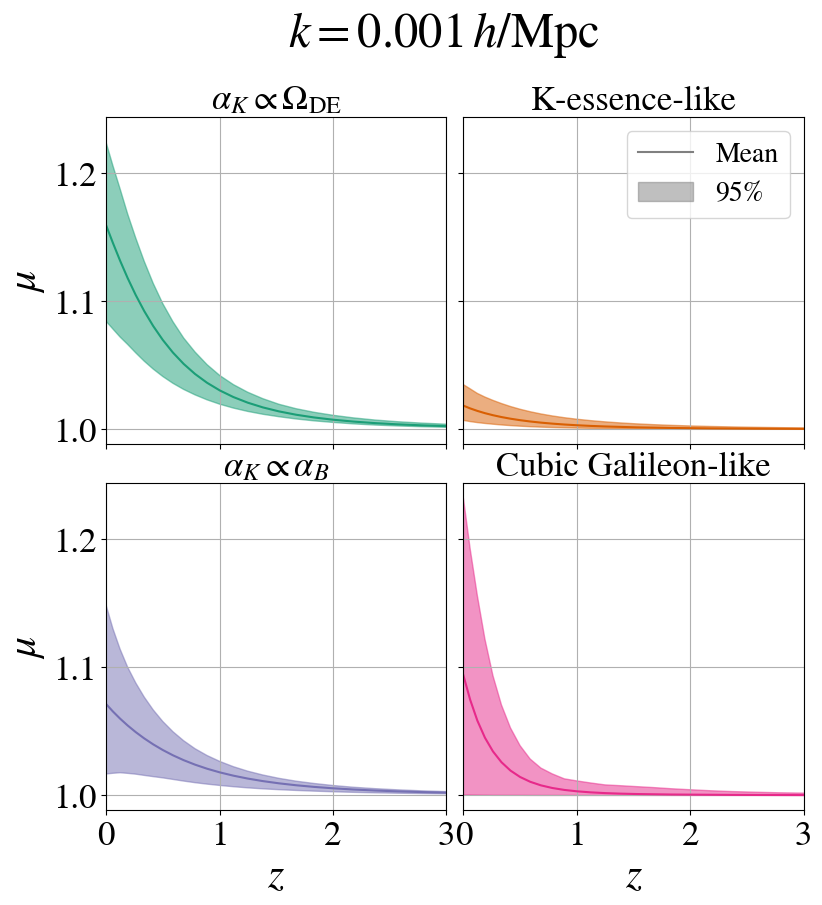

In [4]:
for ik, k in enumerate(k_values):
    mus_all = [mu_ks[:, ik, :] for mu_ks in mu_ks_all]
    utils.plot_mu_distribution(log_a, mus_all, f"plots/constraint_mu_ds1_subluminal_noqsa_k{k:.0e}.pdf", plot_title=f"$k = {k:g}\\,h/\\mathrm{{Mpc}}$")

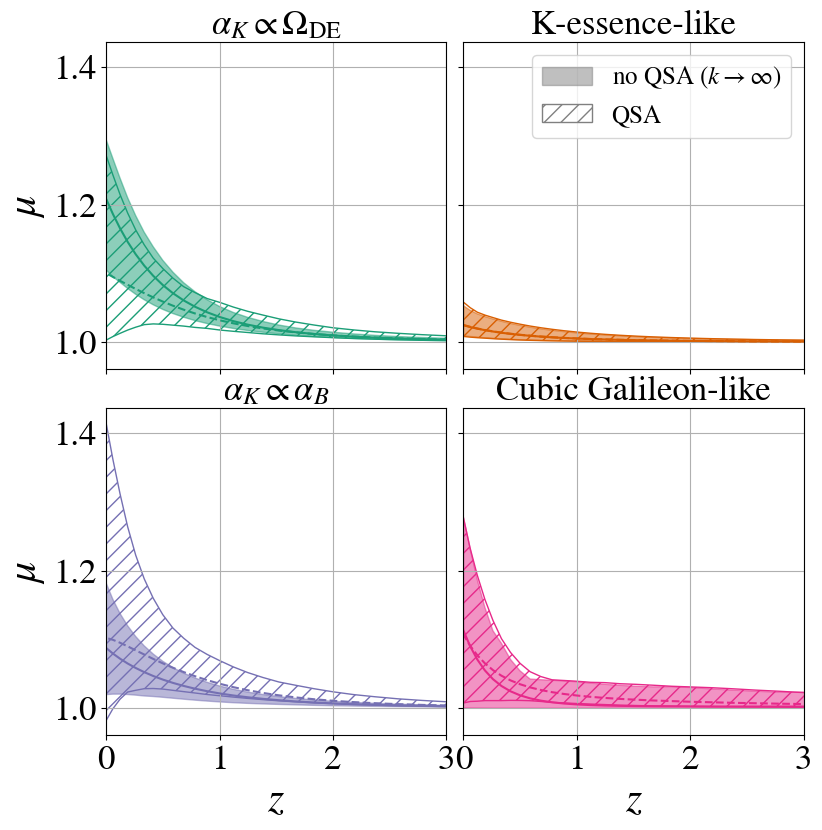

In [5]:
# QSA (hatched) vs no QSA (filled, k -> infinity); bands are 95%
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

titles = ["$\\alpha_K \\propto \\Omega_\\mathrm{DE}$", "K-essence-like", "$\\alpha_K \\propto \\alpha_B$", "Cubic Galileon-like"]
z = 10**-log_a - 1
fig, axs = plt.subplots(2, 2, sharey=True, sharex=True, figsize=(9, 9), gridspec_kw={"wspace": 0.05, "hspace": 0.12})
for i, (ax, title, color) in enumerate(zip(axs.flatten(), titles, utils.colors)):
    ax.plot(z, np.mean(mu_infs_all[i], axis=0), color=color)
    ax.fill_between(z, np.percentile(mu_infs_all[i], 2.5, axis=0), np.percentile(mu_infs_all[i], 97.5, axis=0), color=color, alpha=0.5)
    ax.plot(z, np.mean(mu_qsa_all[i], axis=0), color=color, ls="--")
    ax.fill_between(z, np.percentile(mu_qsa_all[i], 2.5, axis=0), np.percentile(mu_qsa_all[i], 97.5, axis=0), facecolor="none", edgecolor=color, hatch="//")
    ax.set_xlim(0, 3)
    ax.grid()
    if i//2 == 1: ax.set_xlabel("$z$", fontsize=30)
    if i%2 == 0: ax.set_ylabel("$\\mu$", fontsize=30)
    ax.set_title(title, fontsize=25)
    ax.tick_params(axis="both", labelsize=25)
    ax.set_xticks([0, 1, 2, 3])

handles = [Patch(color="gray", alpha=0.5, label="no QSA ($k \\to \\infty$)"), Patch(facecolor="none", edgecolor="gray", hatch="//", label="QSA")]
fig.legend(handles=handles, fontsize=18, bbox_to_anchor=(0.9, 0.88))
plt.savefig("plots/constraint_mu_ds1_subluminal_qsa_vs_noqsa.pdf", bbox_inches="tight")

In [6]:
def print_mu0(label, mus_all):
    print(f"${label}$ & $1$ & ", end="")
    for mus in mus_all:
        mean  = np.mean(mus, axis=0)[-1]
        upper = np.percentile(mus, 50+34, axis=0)[-1] - mean
        lower = mean - np.percentile(mus, 50-34, axis=0)[-1]
        print(f"${mean:.2f}^{{+{upper:.2f}}}_{{-{lower:.2f}}}$ & ", end="")
    print(r" $1$ \\ \hline")

print_mu0("\\mu_0\\ \\mathrm{(QSA)}", mu_qsa_all)
print_mu0("\\mu_0 (k \\to \\infty)", mu_infs_all)
for ik, k in enumerate(k_values):
    print_mu0(f"\\mu_0 (k = {k:g})", [mu_ks[:, ik, :] for mu_ks in mu_ks_all])

$\mu_0\ \mathrm{(QSA)}$ & $1$ & $1.10^{+0.08}_{-0.07}$ & $1.02^{+0.01}_{-0.01}$ & $1.10^{+0.09}_{-0.08}$ & $1.11^{+0.09}_{-0.08}$ &  $1$ \\ \hline
$\mu_0 (k \to \infty)$ & $1$ & $1.21^{+0.06}_{-0.06}$ & $1.02^{+0.01}_{-0.01}$ & $1.09^{+0.04}_{-0.04}$ & $1.11^{+0.10}_{-0.10}$ &  $1$ \\ \hline
$\mu_0 (k = 0.0001)$ & $1$ & $1.01^{+0.00}_{-0.00}$ & $1.00^{+0.00}_{-0.00}$ & $1.00^{+0.00}_{-0.00}$ & $1.01^{+0.00}_{-0.00}$ &  $1$ \\ \hline
$\mu_0 (k = 0.0003)$ & $1$ & $1.05^{+0.01}_{-0.01}$ & $1.01^{+0.00}_{-0.00}$ & $1.02^{+0.01}_{-0.01}$ & $1.04^{+0.03}_{-0.03}$ &  $1$ \\ \hline
$\mu_0 (k = 0.001)$ & $1$ & $1.16^{+0.04}_{-0.04}$ & $1.02^{+0.01}_{-0.01}$ & $1.07^{+0.03}_{-0.03}$ & $1.09^{+0.09}_{-0.08}$ &  $1$ \\ \hline
